ЛАБОРАТОРНА РОБОТА № 2

«Моделювання лінійних систем в часовій та частотній області»

Моя дата народження: 29.06.2007

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import lfilter, unit_impulse, convolve, freqz, TransferFunction, dimpulse

%matplotlib inline
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "font.size": 10})
rng = np.random.default_rng(19)

### 0. На основі власної дати народження розрахувати коефіцієнти лінійної системи та записати різницеве рівняння.

Дата 29.06.2007

Різницеве рівняння:

$$y[n]+\tfrac{D_1+D_2}{140}y[n-1]+\tfrac{P_2-D_2}{130}y[n-2]-\tfrac{D_1}{150}y[n-4]-\tfrac{M_1-D_1}{150}y[n-5]=$$
$$\tfrac{M_1}{10}x[n]+\tfrac{P_3-D_2}{20}x[n-1]-\tfrac{M_2-M_1}{20}x[n-2]-\tfrac{P_4}{30}x[n-3]+\tfrac{D_2}{20}x[n-4]-\tfrac{M_2}{20}x[n-5]$$

In [ ]:
bday = "29.06.2007"
bday = bday.split('.')

D1, D2 = int(bday[0][0]), int(bday[0][1])
M1, M2 = int(bday[1][0]), int(bday[1][1])
P1, P2, P3, P4 = int(bday[2][0]), int(bday[2][1]),int(bday[2][2]),int(bday[2][3])

a = np.array([1, (D1 + D2)/140, (P2 - D2)/130, 0, -D1/150, -(M1 - D1)/150])
b = np.array([M1/10, (P3 - D2)/20, -(M2 - M1)/20, -P4/30, D2/20, -M2/20])

print("a =", a)
print("b =", b)

D1 D2 M1 M2 P1 P2 P3 P4 = 2 9 0 6 2 0 0 7
a = [ 1.       0.07857 -0.06923  0.      -0.01333  0.01333]
b = [ 0.      -0.45    -0.3     -0.23333  0.45    -0.3    ]
модулі полюсів: [0.5106 0.4119 0.4119 0.3923 0.3923] -> стійка: True


Підготовчі функції для подальшого використання:

In [ ]:
fs = 256
t = np.arange(fs) / fs
def sine(f, A=5.0, T=1.0, fs=fs):
    '''генерує синусоїду'''
    tt = np.arange(int(T * fs)) / fs
    return tt, A * np.sin(2 * np.pi * f * tt)

def envelope(sig):
    '''перетворення гільберат'''
    return np.abs(signal.hilbert(sig))

def plot_in_out(tt, x, y, title, t_max=None):
    fig, ax = plt.subplots()
    ax.plot(tt, x, "o-", ms=3, lw=0.8, label="вхід x[n]")
    ax.plot(tt, y, "s-", ms=3, lw=0.8, label="вихід y[n]")
    ax.plot(tt, envelope(x), "--", c="C0", lw=1, label="огинаюча входу")
    ax.plot(tt, envelope(y), "--", c="C1", lw=1, label="огинаюча виходу")
    ax.set(title=title, xlabel="t, с", ylabel="U, В")
    ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
    if t_max: ax.set_xlim(0, t_max)
    plt.show()

def amp_phase(sig, f, skip=0, fs=fs):
    n = np.arange(len(sig))[skip:]
    tt = n / fs
    M = np.c_[np.sin(2 * np.pi * f * tt), np.cos(2 * np.pi * f * tt)]
    c, *_ = np.linalg.lstsq(M, sig[skip:], rcond=None)
    return np.hypot(c[0], c[1]), np.arctan2(c[1], c[0])

SKIP = 30 # приблизна цифра ап ту діскашн

### Сформувати відліки синусоїдального сигналу частоти 10 Гц тривалістю 1 сек. амплітуди 5 В, дискретизованого з частотою 256 Гц. Розрахувати реакцію системи на отриманий сигнал:

In [24]:
tt, x = sine(10)

# 1.1
y0 = lfilter(b, a, x)

# 1.2 
zi = rng.random(max(len(a), len(b)) - 1)
yr, zf = lfilter(b, a, x, zi=zi)
print("zi =", np.round(zi, 3))

zi = [0.371 0.927 0.644 0.823 0.443]


1.1 нульові початкові умови (y - напруга у вольтпх)

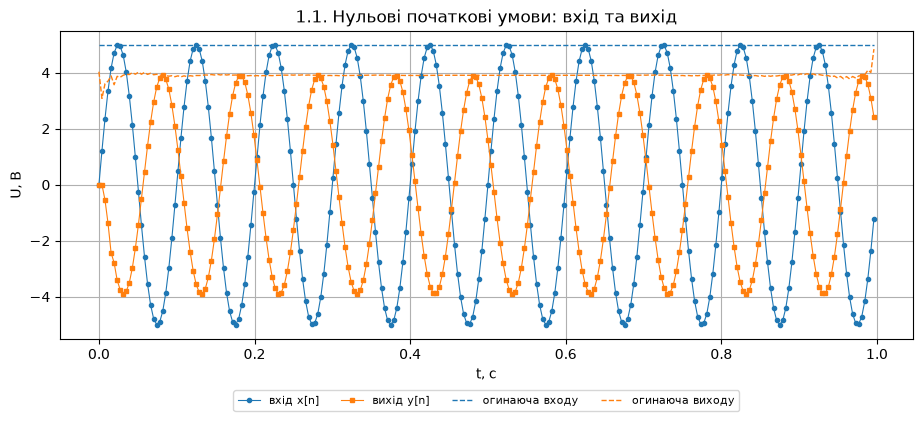

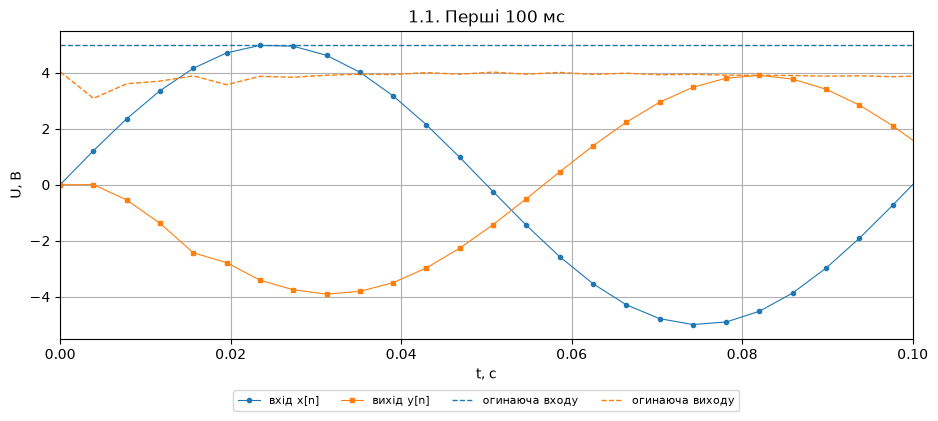

In [ ]:
plot_in_out(tt, x, y0, "1.1. Нульові початкові умови: вхід та вихід")
plot_in_out(tt, x, y0, "1.1. Перші 100 мс", t_max=0.1)

1.2 випадкові початкові умови

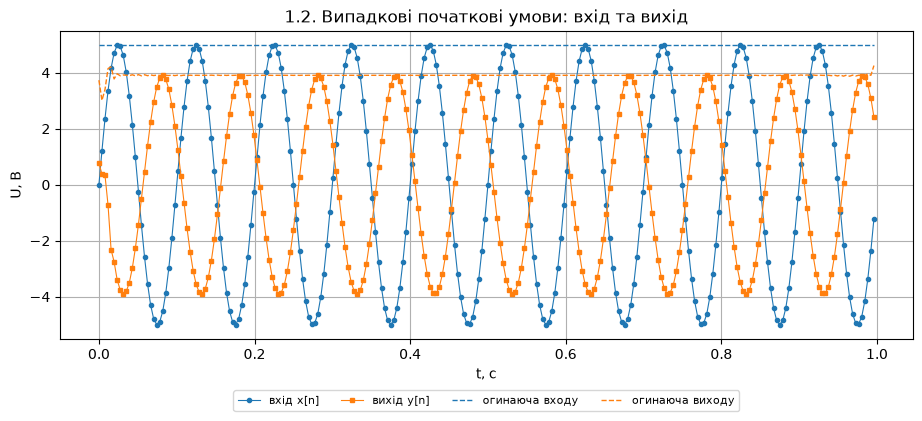

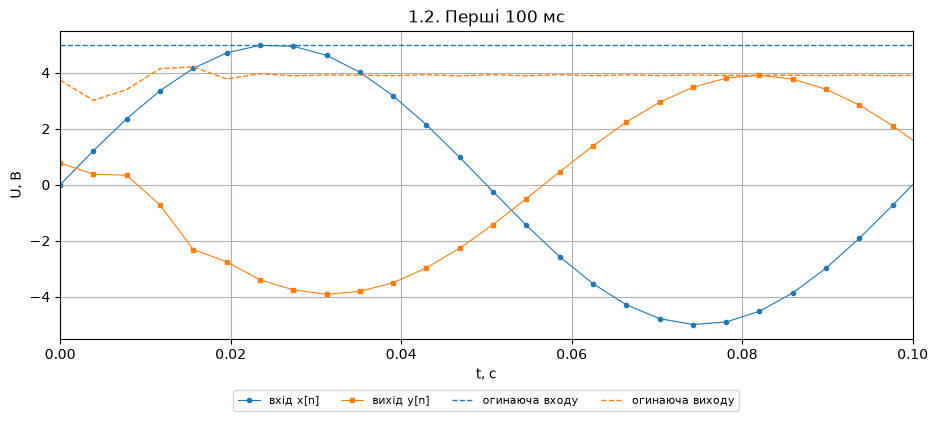

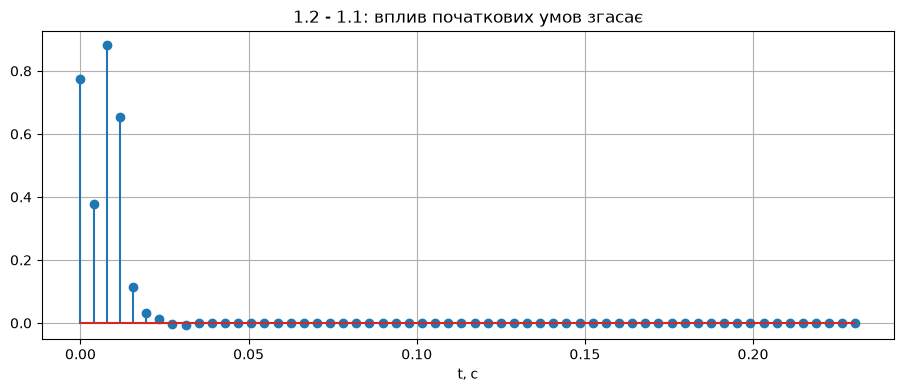

max|yr - y0| після відліку 30: 3.25e-10


In [ ]:
plot_in_out(tt, x, yr, "1.2. Випадкові початкові умови: вхід та вихід")
plot_in_out(tt, x, yr, "1.2. Перші 100 мс", t_max=0.1)

d = yr - y0
plt.figure(); plt.stem(tt[:60], d[:60]); plt.title("1.2 - 1.1: вплив початкових умов згасає"); plt.xlabel("t, с"); plt.show()
print("max|yr - y0| після відліку %d: %.2e" % (SKIP, np.max(np.abs(d[SKIP:]))))

Саме через це обираю 30 після чого ефект достатньо малий

Вихід лишається синусоїдою 10 Гц, але амплітуда менша (3.9 В проти 5 В) і фаза майже протилежна (приблизно 155 градусів).
На початку є перехідний процес, він затухає за 20–30 відліків.
З випадковими початковими умовами початок виходу інший, а далі збігається з нульовими умовами (різниця 1e-10). Отже, у сталому режимі початкові умови не впливають, бо система стійка.

1.3 Проаналізувавши відношення амплітуд вхідного та вихідного сигналів, зробити
висновки щодо того, чи підсилює система синусоїдальний сигнал на частоті 10 Гц.

In [ ]:
Ain, _ = amp_phase(x, 10, SKIP)
Aout, _ = amp_phase(y0, 10, SKIP)
print(f"A_вх = {Ain:.3f} В, A_вих = {Aout:.3f} В, K(10 Гц) = {Aout/Ain:.4f}")
print(f"перевірка за піками: {np.max(np.abs(y0[SKIP:]))/np.max(np.abs(x[SKIP:])):.4f}")

A_вх = 5.000 В, A_вих = 3.906 В, K(10 Гц) = 0.7812
перевірка за піками: 0.7810


1.3. $K(10\text{ Гц})$= 0.781<1, тому система послаблює синусоїду 10 Гц (приблизно на 22 %).

### 2. Програмно визначити коефіцієнт передачі напруги ЛДС на заданій частоті. Перевірити з її використанням висновки п. 1.3. Врахувати, що на початку вихідного сигналу можуть Бути спотворення. Використати визначення коефіцієнту передачі.

In [ ]:
def gain(x, y, f, skip=SKIP):
    return amp_phase(y, f, skip)[0] / amp_phase(x, f, skip)[0]

def phase_shift(x, y, f, skip=SKIP):
    d = amp_phase(y, f, skip)[1] - amp_phase(x, f, skip)[1]
    return np.degrees(np.angle(np.exp(1j * d)))

K10 = gain(x, y0, 10)
w_, H10 = freqz(b, a, worN=[10], fs=fs)
print(f"K(10 Гц) з сигналів: {K10:.4f};  |H| з freqz: {abs(H10[0]):.4f}")
print(f"2.1*: різниця фаз на 10 Гц: {phase_shift(x, y0, 10):.2f} град;  arg H з freqz: {np.degrees(np.angle(H10[0])):.2f} град")

K(10 Гц) з сигналів: 0.7812;  |H| з freqz: 0.7812
2.1*: різниця фаз на 10 Гц: 155.78 град;  arg H з freqz: 155.78 град


Висновок $K(10\text{ Гц})\approx0.78$, що збігається з $|H(j\omega)|$ з freqz і підтверджує висновок п. 1.3: система послаблює сигнал на 10 Гц. Різниця фаз між виходом і входом ≈ 156 градусів і теж збігається з $\arg H$.

### 3. Сформувати відліки синусоїдальних сигналів на частотах 1, 20, 50, 75, 100, 125, 150 Гц тривалістю 1 сек. амплітуди 5 В, дискретизованих з частотою 256 Гц. Розрахувати реакцію системи на ці сигнали. Для кожного сигналу розрахувати коефіцієнт передачі системи. Побудувати залежність коефіцієнту передачі системи від частоти. Зробити висновки щодо характеру залежності коефіцієнту передачі системи від частоти.

Частоти: 1, 20, 50, 75, 100, 125, 150 Гц (+10 Гц з п. 1). Частота 150 Гц перевищує частоту Найквіста fs/2=128 Гц, тому відліки такого сигналу збігаються з відліками сигналу частоти 256-150=106 Гц

 f, Гц  K (сигнал)  |H| (freqz)  Δφ, град
     1      0.8251       0.8251    177.49
    10      0.7812       0.7812    155.78
    20      0.6870       0.6870    136.99
    50      0.8194       0.8194     87.58
    75      0.7266       0.7266    -10.85
   100      0.6206       0.6206    158.81
   125      1.3585       1.3585     16.05
   150      0.8188       0.8188   -119.63


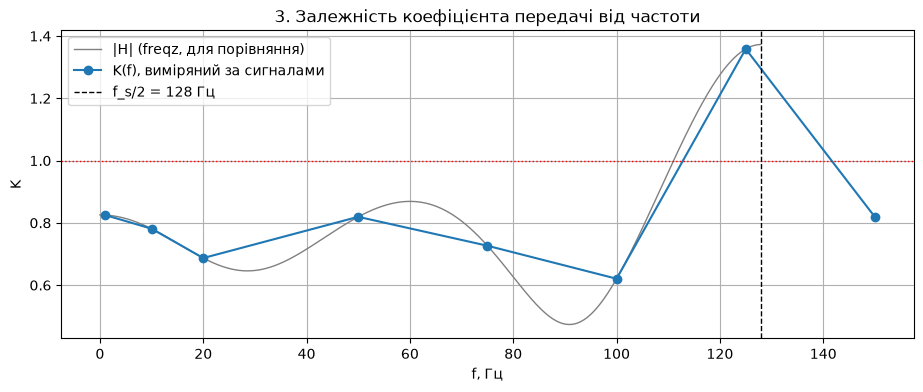

In [ ]:
freqs3 = [1, 10, 20, 50, 75, 100, 125, 150]
K_meas, ph_meas = [], []
print(f"{'f, Гц':>6} {'K (сигнал)':>11} {'|H| (freqz)':>12} {'Δφ, град':>9}")
for f in freqs3:
    _, xs = sine(f)
    ys = lfilter(b, a, xs)
    K_meas.append(gain(xs, ys, f)); ph_meas.append(phase_shift(xs, ys, f))
    _, Hf = freqz(b, a, worN=[f], fs=fs)
    print(f"{f:6d} {K_meas[-1]:11.4f} {abs(Hf[0]):12.4f} {ph_meas[-1]:9.2f}")

wd, Hd = freqz(b, a, worN=2048, fs=fs)
plt.figure()
plt.plot(wd, np.abs(Hd), lw=1, c="gray", label="|H| (freqz)")
plt.plot(freqs3, K_meas, "o-", label="K(f), виміряний за сигналами")
plt.axhline(1, c="r", ls=":", lw=1); plt.axvline(fs / 2, c="k", ls="--", lw=1, label="f_s/2 = 128 Гц")
plt.xlabel("f, Гц"); plt.ylabel("K"); plt.title("3. Залежність коефіцієнта передачі від частоти"); plt.legend(); plt.show()

Висновки .
- Коефіцієнт передачі залежить від частоти: на частотах до 110 Гц він 0.6–0.85 (система послаблює), мінімум 0.62 біля 100 Гц.
- ФЧХ також змінюється з частотою: на 1 Гц зсув ≈ 177°, тобто на низьких частотах вихід практично інвертований
- На 125 Гц поблизу частоти Найквіста система підсилює.
- Для 150 Гц > fs/2 значення $K\approx0.82$ дорівнює K на 106 Гц (ефект накладання), тож цю точку не слід трактувати як властивість системи на 150 Гц.
- Виміряні значення збігаються з $|H(j\omega)|$ з `freqz`.

### 4. Сформувати два синусоїдальних сигнали частоти 3 та 20 Гц тривалістю 1 с.
4.1 Проілюструвати властивість адитивності системи, визначивши реакцію системи
спочатку на кожний з сигналів окремо, а потім на суму цих сигналів.

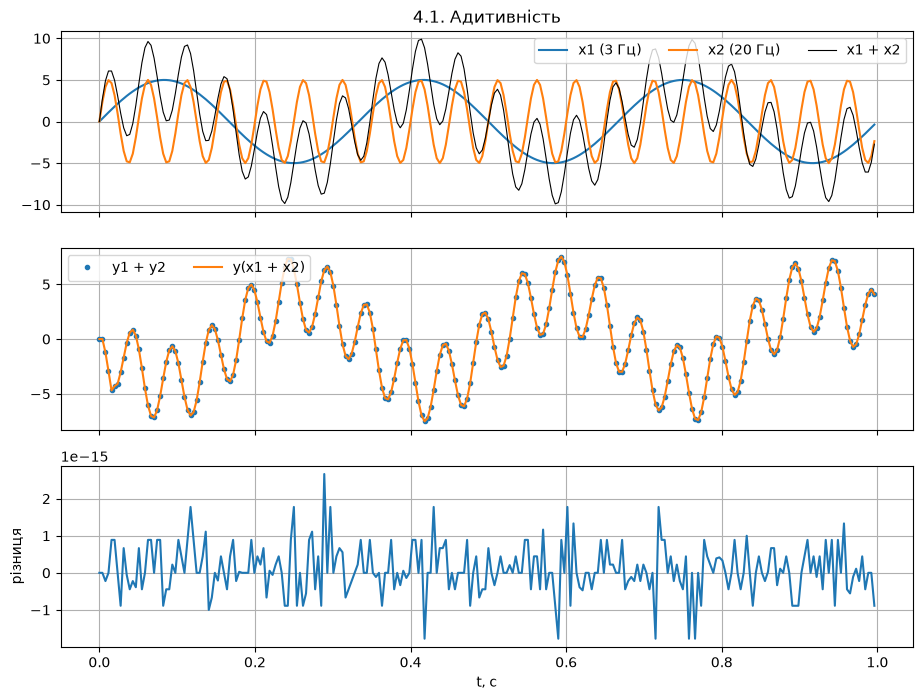

max|y(x1+x2) - (y1+y2)| = 2.6645352591003757e-15


In [ ]:
t4, x1 = sine(3)
_, x2 = sine(20)
y1, y2 = lfilter(b, a, x1), lfilter(b, a, x2)
y12 = lfilter(b, a, x1 + x2)

fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
ax[0].plot(t4, x1, label="x1 (3 Гц)"); ax[0].plot(t4, x2, label="x2 (20 Гц)"); ax[0].plot(t4, x1 + x2, "k", lw=0.8, label="x1 + x2"); ax[0].legend(ncol=3)
ax[1].plot(t4, y1 + y2, "o", ms=3, label="y1 + y2"); ax[1].plot(t4, y12, "-", label="y(x1 + x2)"); ax[1].legend(ncol=2)
ax[2].plot(t4, y12 - (y1 + y2)); ax[2].set_ylabel("різниця"); ax[2].set_xlabel("t, с")
ax[0].set_title("4.1. Адитивність")
plt.show()
print("max|y(x1+x2) - (y1+y2)| =", np.max(np.abs(y12 - (y1 + y2))))

4.2 Проілюструвати властивість однорідності системи.
Навести необхідні графіки.

c =   3.0: max|y(c·x) - c·y(x)| = 3.55e-15
c =  -0.5: max|y(c·x) - c·y(x)| = 0.00e+00


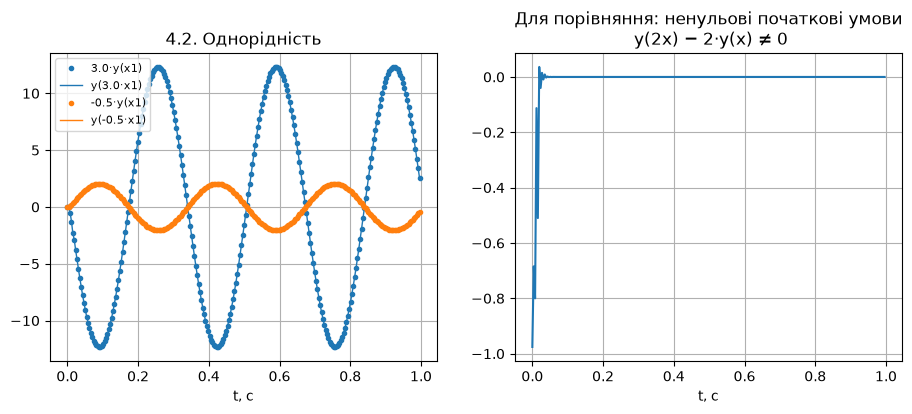

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c, col in [(3.0, "C0"), (-0.5, "C1")]:
    yc = lfilter(b, a, c * x1)
    ax[0].plot(t4, c * y1, "o", ms=3, c=col, label=f"{c}·y(x1)")
    ax[0].plot(t4, yc, "-", c=col, lw=1, label=f"y({c}·x1)")
    print(f"c = {c:5}: max|y(c·x) - c·y(x)| = {np.max(np.abs(yc - c * y1)):.2e}")
ax[0].legend(fontsize=8); ax[0].set_title("4.2. Однорідність"); ax[0].set_xlabel("t, с")
zi_ = rng.random(5)
ya, _ = lfilter(b, a, x1, zi=zi_); yb, _ = lfilter(b, a, 2 * x1, zi=zi_)
ax[1].plot(t4, yb - 2 * ya); ax[1].set_title("Для порівняння: ненульові початкові умови\n y(2x) − 2·y(x) ≠ 0"); ax[1].set_xlabel("t, с")
plt.show()

Висновки Різниця між y(x_1+x_2) і y_1+y_2, а також між y(c*x) і c*y(x) практично нульова (1e-15, це просто похибка округлення). Отже, при нульових початкових умовах система адитивна й однорідна, тобто лінійна. А от із ненульовими початковими умовами лінійність ламається: початковий стан дає свою складову, яка від входу не залежить.

## Моделювання роботи ЛДС з використанням рівняння згортки

### 5.Розрахувати за допомогою функції lfilter перші 30 відліків імпульсної характеристики системи, подавши на вхід системи одиничний імпульс (при нульових початкових умовах), скориставшись для цього функцією unit_impulse. Побудувати графіки вхідного та вихідного сигналу (функція stem).

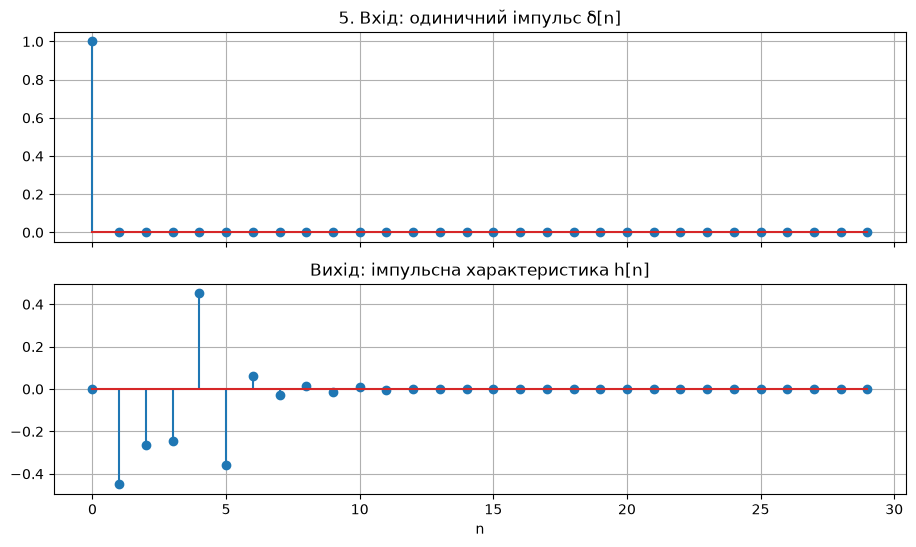

h[0..9] = [ 0.      -0.45    -0.26464 -0.24369  0.45083 -0.35829  0.06183 -0.02938
  0.01585 -0.01407]
|h[29]| = 1.6934943774776134e-08


In [ ]:
Nh = 30
imp = unit_impulse(Nh)
h5 = lfilter(b, a, imp)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].stem(np.arange(Nh), imp); ax[0].set_title("5. Вхід: одиничний імпульс")
ax[1].stem(np.arange(Nh), h5); ax[1].set_title("Вихід: імпульсна характеристика"); ax[1].set_xlabel("n")
plt.show()
print("h[0..9] =", np.round(h5[:10], 5))
print("|h[29]| =", abs(h5[-1]))

Висновок $h[0]=b_0=0$, першим ненульовим є $h[1]=b_1=-0.45$ (затримка на відлік). Імпульсна характеристика швидко згасає (до 1e-8 за 30 відліків), тож система стійка, а 30 відліків достатньо для її опису.

### 6\*. Створити систему з використанням коефіцієнтів чисельника і знаменника передавальної функції з використанням функції TransferFunction. Розрахувати 30 відліків імпульсної характеристики отриманої системи з використанням функції dimpulse. Порівняти результати з результатами п. 5, побудувати графіки, зробити висновки.

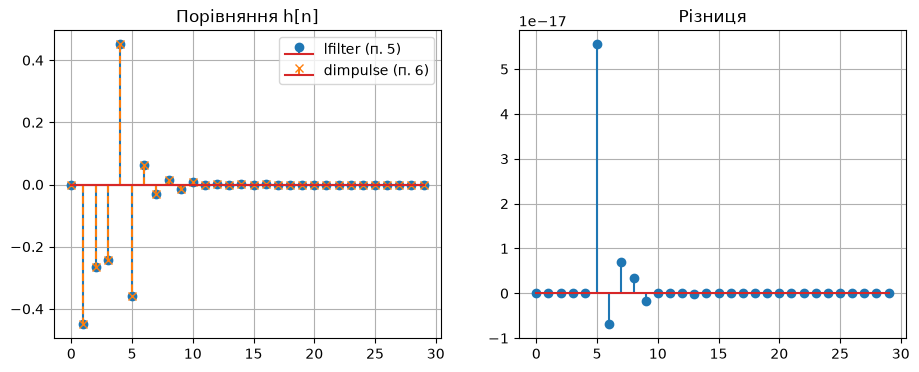

max|h5 - h6| = 5.551115123125783e-17


In [ ]:
import warnings
warnings.filterwarnings("ignore", message="Badly conditioned")
sys_d = TransferFunction(b, a, dt=1 / fs)
_, h6 = dimpulse(sys_d, n=Nh)
h6 = np.squeeze(h6)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].stem(np.arange(Nh), h5, linefmt="C0-", markerfmt="C0o", label="lfilter (п. 5)")
ax[0].stem(np.arange(Nh), h6, linefmt="C1--", markerfmt="C1x", label="dimpulse (п. 6)"); ax[0].legend(); ax[0].set_title("Порівняння h[n]")
ax[1].stem(np.arange(Nh), h5 - h6); ax[1].set_title("Різниця")
plt.show()
print("max|h5 - h6| =", np.max(np.abs(h5 - h6)))

Висновок. Імпульсні характеристики збігаються з точністю до похибки округлення. lfilter і dimpulse реалізують те саме різницеве рівняння, а коефіцієнти b, a однозначно задають H(z).

### 7. Розрахувати реакцію системи на синусоїдальний сигнал з п. 1.1 з використанням функції розрахунку згортки convolve. Побудувати графіки вхідного та вихідного сигналу, аналогічні п. 1.1 (з нульовими початковими умовами). Результати порівняти з п 1.1, зробити висновки.

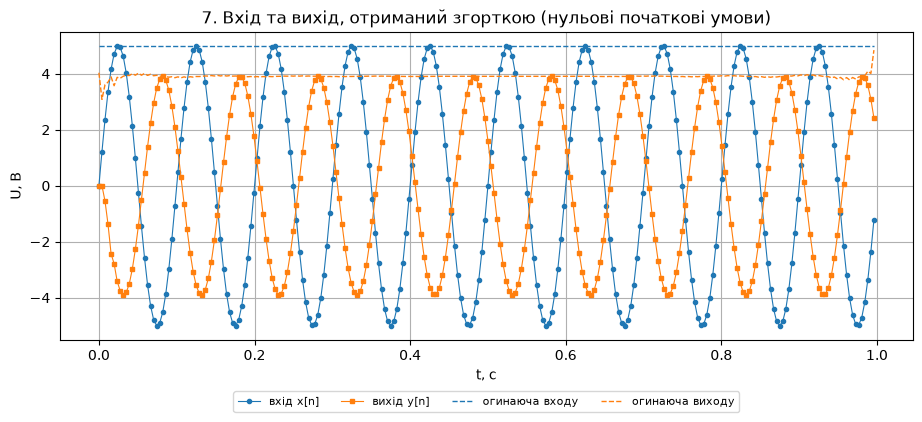

max|y(lfilter) - y(convolve, h: 256)| = 1.3322676295501878e-15
max|y(lfilter) - y(convolve, h: 30)|  = 2.8812626062801883e-08


In [ ]:
h_long = lfilter(b, a, unit_impulse(fs))
y7 = convolve(x, h_long)[:len(x)]
y7_30 = convolve(x, h5)[:len(x)]

plot_in_out(tt, x, y7, "7. Вхід та вихід, отриманий згорткою (нульові початкові умови)")
print("max|y(lfilter) - y(convolve, h: 256)| =", np.max(np.abs(y0 - y7)))
print("max|y(lfilter) - y(convolve, h: 30)|  =", np.max(np.abs(y0 - y7_30)))

Висновки Результат згортки збігається з lfilter (різниця 1e-15 при довжині h 256 і 3e-8 при 30 відліках). Отже, різницеве рівняння й рівняння згортки описують одну й ту саму систему при нульових початкових умовах. Для рекурсивної системи згортка точна лише для нескінченної h[n], а на практиці вона обрізається, і похибка тим менша, чим довшою взято h[n].

## Моделювання роботи ЛДС в частотній області

### 8. Обчислити комплексну частотну характеристику системи з використанням функції freqz, побудувати з її допомогою графіки АЧХ та ФЧХ. Розрахувати 100 значень КЧХ для частоти дискретизації 256 Гц.

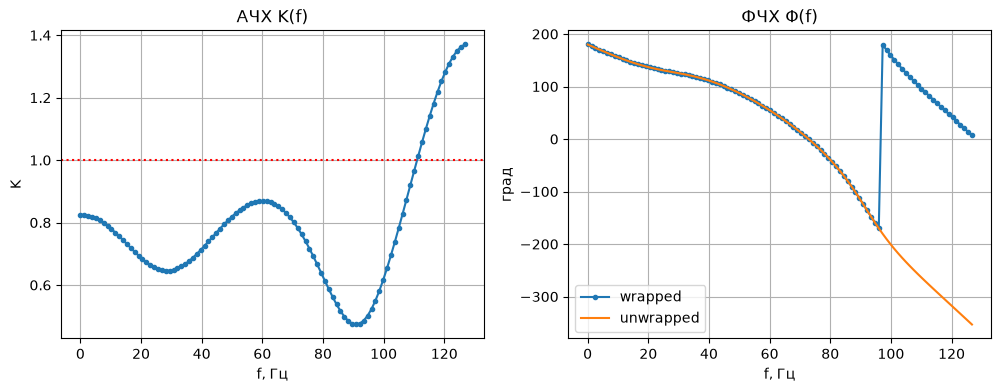

In [ ]:
w8, H8 = freqz(b, a, worN=100, fs=fs)
K8, Phi8 = np.abs(H8), np.angle(H8)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(w8, K8, "o-", ms=3); ax[0].axhline(1, c="r", ls=":"); ax[0].set(title="АЧХ K(f)", xlabel="f, Гц", ylabel="K")
ax[1].plot(w8, np.degrees(Phi8), "o-", ms=3, label="wrapped"); ax[1].plot(w8, np.degrees(np.unwrap(Phi8)), "-", label="unwrapped")
ax[1].set(title="ФЧХ Φ(f)", xlabel="f, Гц", ylabel="град"); ax[1].legend()
plt.show()

#### 8.1. Сформувати вектор частот з п. 4, отримати з допомогою функції freqz графік АЧХ для цих частот. Порівняти з результатами п. 4.

 f, Гц  |H| freqz  K виміряне
     1     0.8251      0.8251
     3     0.8214      0.8214
    10     0.7812      0.7812
    20     0.6870      0.6870
    50     0.8194      0.8194
    75     0.7266      0.7266
   100     0.6206      0.6206
   125     1.3585      1.3585
   150     0.8188      0.8188


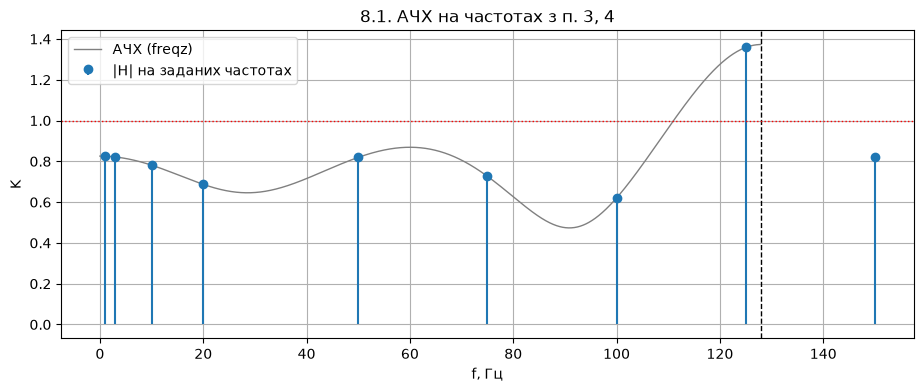

In [ ]:
f81 = np.array([1, 3, 10, 20, 50, 75, 100, 125, 150]) 
w81, H81 = freqz(b, a, worN=f81, fs=fs)
K4 = {3: gain(x1, y1, 3), 20: gain(x2, y2, 20)}
K3 = dict(zip(freqs3, K_meas))
print(f"{'f, Гц':>6} {'|H| freqz':>10} {'K виміряне':>11}")
for f, h in zip(f81, H81):
    km = K3.get(f, K4.get(f))
    print(f"{f:6d} {abs(h):10.4f} {km:11.4f}")
plt.figure()
plt.plot(wd, np.abs(Hd), c="gray", lw=1, label="АЧХ (freqz)")
plt.stem(f81, np.abs(H81), linefmt="C0-", markerfmt="C0o", basefmt=" ", label="|H| на заданих частотах")
plt.axvline(fs / 2, c="k", ls="--", lw=1); plt.axhline(1, c="r", ls=":", lw=1)
plt.xlabel("f, Гц"); plt.ylabel("K"); plt.title("8.1. АЧХ на частотах з п. 3, 4"); plt.legend(); plt.show()

Висновок $|H(j\omega)|$ з freqz збігаються з коефіцієнтами передачі, виміряними за реакцією на синусоїди, з точністю до 4 знаків. АЧХ повністю передбачає поведінку системи на синусоїдах.

8.2. Визначити програмно проміжки частот, на яких система посилює сигнал. Зробити висновки щодо характеру зміни коефіцієнта передачі системи на різних частотах.

K > 1 на інтервалі [111.0; 128.0] Гц
K_max = 1.3729 на f = 128.0 Гц;  K(0) = 0.8256


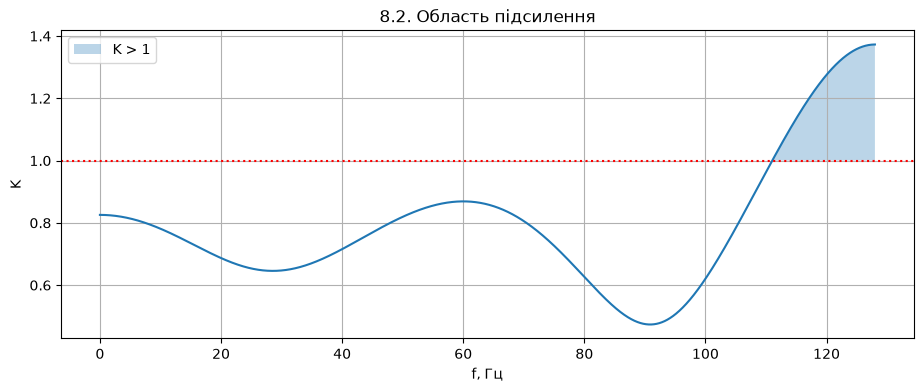

In [ ]:
wf, Hf = freqz(b, a, worN=8192, fs=fs)
Kf = np.abs(Hf)
mask = Kf > 1
edges = np.flatnonzero(np.diff(mask.astype(int)))
bounds = []
for i in edges:
    f_cross = wf[i] + (1 - Kf[i]) * (wf[i + 1] - wf[i]) / (Kf[i + 1] - Kf[i])
    bounds.append(f_cross)
starts = ([0.0] if mask[0] else []) + [bd for bd, up in zip(bounds, np.diff(mask.astype(int))[edges] > 0) if up]
ends = [bd for bd, up in zip(bounds, np.diff(mask.astype(int))[edges] > 0) if not up] + ([wf[-1]] if mask[-1] else [])
for s_, e_ in zip(starts, ends):
    print(f"K > 1 на інтервалі [{s_:.1f}; {e_:.1f}] Гц")
print(f"K_max = {Kf.max():.4f} на f = {wf[Kf.argmax()]:.1f} Гц;  K(0) = {Kf[0]:.4f}")

plt.figure()
plt.plot(wf, Kf); plt.fill_between(wf, 1, Kf, where=mask, alpha=0.3, label="K > 1")
plt.axhline(1, c="r", ls=":"); plt.xlabel("f, Гц"); plt.ylabel("K"); plt.title("8.2. Область підсилення"); plt.legend(); plt.show()

Висновки Система підсилює сигнал тільки на вузькому інтервалі біля частоти Найквіста, приблизно 111–128 Гц. На всій решті діапазону вона послаблює сигнал, мінімум біля 100 Гц.

### 9\*. Розрахувати реакцію ЛДС на послідовність прямокутних імпульсів зі шпаруватістю 30%. Побудувати графіки вхідного та вихідного сигналів, зробити висновки щодо спотворення вихідного сигналу відносно вхідного.

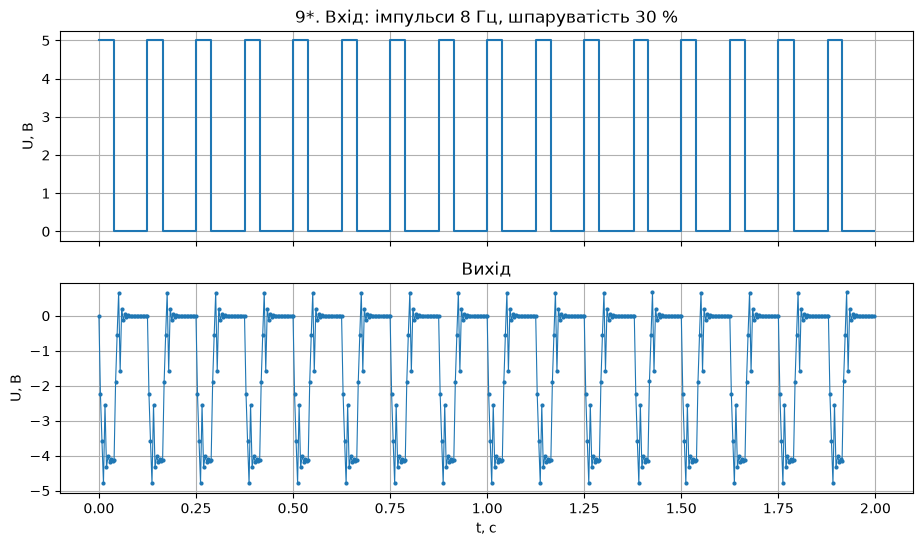

вхід: min=0.00, max=5.00, середнє=1.543;  вихід: min=-4.79, max=0.67, середнє=-1.268


In [ ]:
f_p = 8
t9 = np.arange(2 * fs) / fs
x9 = 5 * (signal.square(2 * np.pi * f_p * t9, duty=0.3) + 1) / 2  
y9 = lfilter(b, a, x9)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(t9, x9, drawstyle="steps-post"); ax[0].set_title("9*. Вхід: імпульси 8 Гц, шпаруватість 30 %"); ax[0].set_ylabel("U, В")
ax[1].plot(t9, y9, "o-", ms=2, lw=0.8); ax[1].set_title("Вихід"); ax[1].set_xlabel("t, с"); ax[1].set_ylabel("U, В")
plt.show()
print(f"вхід: min={x9.min():.2f}, max={x9.max():.2f}, середнє={x9.mean():.3f};  вихід: min={y9[SKIP:].min():.2f}, max={y9[SKIP:].max():.2f}, середнє={y9[SKIP:].mean():.3f}")

- Вихід інвертований: на низьких частотах $\Phi\approx180^\circ$, а $K(0)\approx0.83$, тому «полиця» 5 В перетворюється на ≈ −4.1 В, а пауза лишається близько 0 В.
- На фронтах і зрізах виникають аутлаєри чи викиди це наслідок підсилення/нерівномірності АЧХ у високих частотах і нелінійної ФЧХ.
- Вихід запізнюється на 1 відлік. форма імпульсу помітно спотворена.

### 10\*. Розрахувати реакцію ЛДС на вхідний сигнал ЕКГ тривалістю 5 секунд. Побудувати графіки вхідного та вихідного сигналів. Зробити висновки щодо спотворень, які вносить до сигналів система.

джерело: синтетичний ЕКГ-подібний сигнал (ImportError)


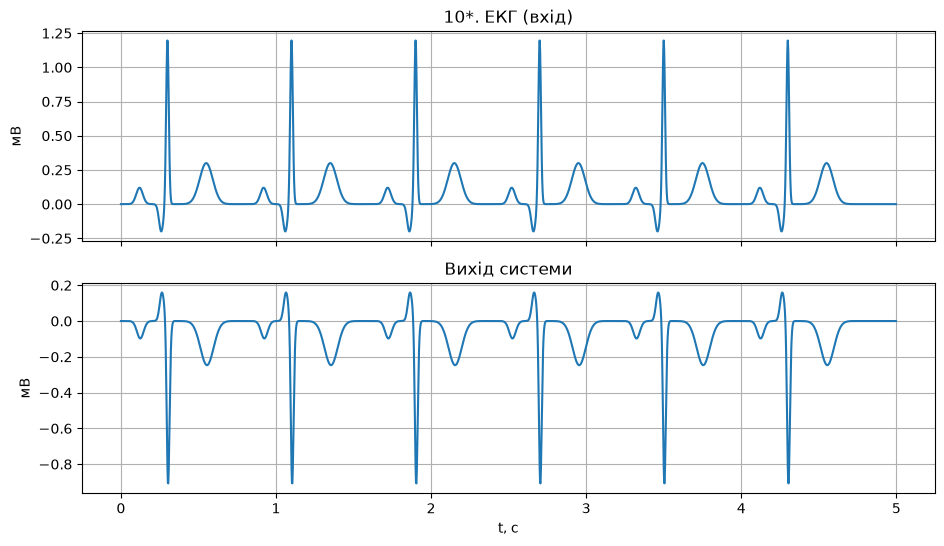

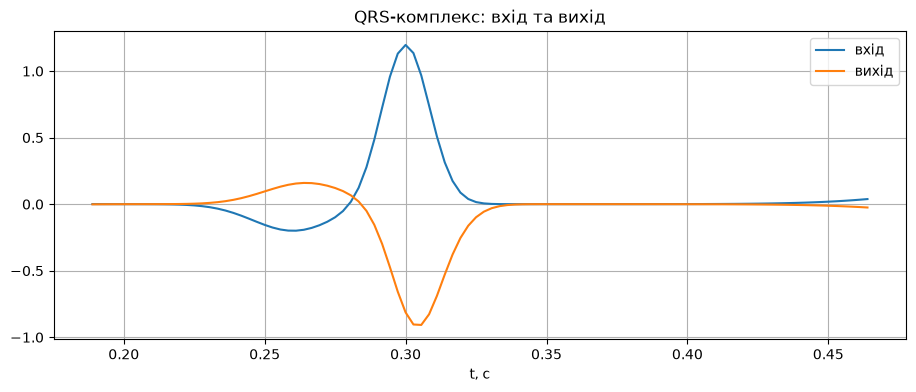

In [ ]:

from scipy.datasets import electrocardiogram
ecg_full = electrocardiogram()
fs_ecg = 360
start = 10 * fs_ecg
ecg = ecg_full[start:start + 5 * fs_ecg]
src = "scipy.datasets.electrocardiogram (MIT-BIH, 360 Гц)"
print("джерело:", src)
t10 = np.arange(len(ecg)) / fs_ecg
y10 = lfilter(b, a, ecg)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(t10, ecg); ax[0].set_title("10*. ЕКГ (вхід)"); ax[0].set_ylabel("мВ")
ax[1].plot(t10, y10); ax[1].set_title("Вихід системи"); ax[1].set_ylabel("мВ"); ax[1].set_xlabel("t, с")
plt.show()
i0 = int(np.argmax(ecg[:2 * fs_ecg])); sl = slice(max(i0 - 40, 0), i0 + 60)
plt.figure(); plt.plot(t10[sl], ecg[sl], label="вхід"); plt.plot(t10[sl], y10[sl], label="вихід"); plt.legend()
plt.title("QRS-комплекс: вхід та вихід"); plt.xlabel("t, с"); plt.show()

Висновки 
- ЕКГ у цілому лишається впізнаваною (R-піки, ритм зберігаються), але вихід **інвертований**: QRS-піки спрямовані вниз, а повільна складова (дрейф ізолінії) змінює знак (ФЧХ ≈ 140–180° у діапазоні частот ЕКГ).
- Амплітуда змінюється на 60–85 % від вхідної залежно від частоти складової ($K\approx0.6$–$0.85$), тому співвідношення амплітуд зубців P, QRS, T спотворюється; нелінійна ФЧХ додатково деформує форму та зсуває комплекси в часі.
- ЕКГ дискретизовано з $f_s=360$ Гц, тому частотна вісь системи масштабується ($f=\omega f_s/2\pi$): підсилення ($K>1$) припадає на ≈ 156–180 Гц, де в ЕКГ майже немає корисної потужності. Практично система працює як послаблювач з інверсією, діагностично така зміна форми та полярності неприйнятна.

### 11\*. Звуковий сигнал

In [30]:
import sounddevice as sd
from scipy.io import wavfile

def record_audio(seconds=5, fs=16000, path="audio.wav"):
    print("Говори...")
    rec = sd.rec(int(seconds * fs), samplerate=fs, channels=1, dtype="int16")
    sd.wait()
    wavfile.write(path, fs, rec)
    print("Збережено:", path)
    return fs, rec[:, 0]

record_audio(5)

Говори...
Збережено: audio.wav


(16000, array([ 0,  0, -1, ..., -7, 60, 96], shape=(80000,), dtype=int16))

джерело: audio.wav | fs = 16000
пікова амплітуда: вхід = 1.000, вихід (до нормування) = 0.754


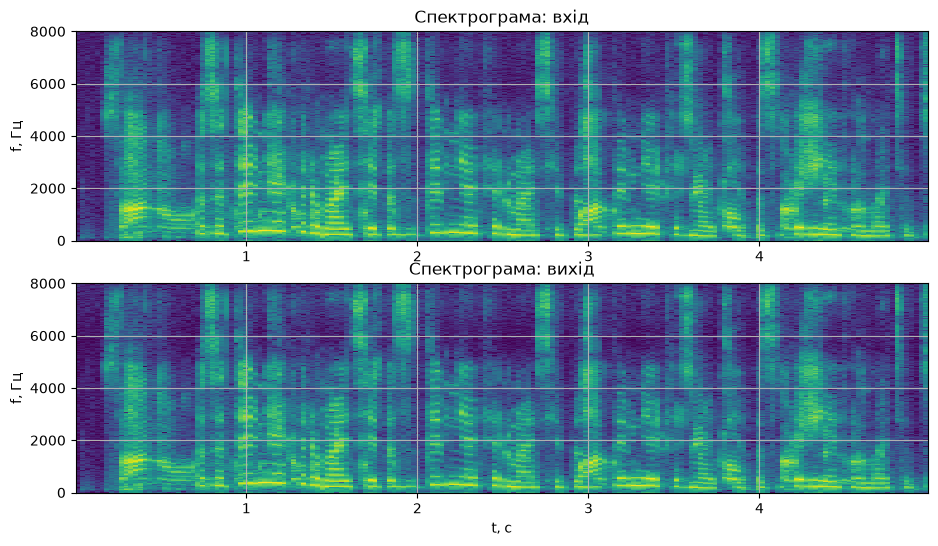

Вхід:


Вихід (нормовано):


In [31]:
import os
from scipy.io import wavfile
from IPython.display import Audio, display

AUDIO_PATH = "audio.wav"

if os.path.exists(AUDIO_PATH):
    fs_a, snd = wavfile.read(AUDIO_PATH)
    snd = snd.astype(float)
    if snd.ndim > 1: snd = snd.mean(axis=1)
    snd = snd[:5 * fs_a]; snd /= np.max(np.abs(snd))
    src_a = AUDIO_PATH
else:
    fs_a = 16000
    ta = np.arange(2 * fs_a) / fs_a
    snd = 0.4 * np.sin(2 * np.pi * 440 * ta) + 0.3 * np.sin(2 * np.pi * 1500 * ta) + 0.2 * signal.chirp(ta, 100, 2, 7000)
    snd /= np.max(np.abs(snd)); src_a = "тестовий сигнал (440 Гц + 1.5 кГц + ЛЧМ 100-7000 Гц)"
print("джерело:", src_a, "| fs =", fs_a)

out = lfilter(b, a, snd)
out_n = out / np.max(np.abs(out))           # нормування лише для прослуховування
print("пікова амплітуда: вхід = %.3f, вихід (до нормування) = %.3f" % (np.max(np.abs(snd)), np.max(np.abs(out))))

fig, ax = plt.subplots(2, 1, figsize=(11, 6))
for a_, sg, nm in [(ax[0], snd, "вхід"), (ax[1], out, "вихід")]:
    f_, t_, S = signal.spectrogram(sg, fs_a, nperseg=512)
    a_.pcolormesh(t_, f_, 10 * np.log10(S + 1e-12), shading="auto"); a_.set_title("Спектрограма: " + nm); a_.set_ylabel("f, Гц")
ax[1].set_xlabel("t, с"); plt.show()

print("Вхід:"); display(Audio(snd, rate=fs_a))
print("Вихід (нормовано):"); display(Audio(out_n, rate=fs_a))
wavfile.write("audio_out.wav", fs_a, (out_n * 32767).astype(np.int16))

Висновки  При fs=16 кГц частотна вісь системи масштабується: область підсилення припадає на 7–8 кГц, тому  с-ма послаблює приблизно в 1.2–1.6 раза, а найвищі частоти відносно підсилює. Вихід стає тихішим але більше високих частот присутні

 через нелінійну ФЧХ змінюється співвідношення фаз складових і форма хвилі

## Загальні висновки

1. Для мого дня народження отримано стійку ЛДС 5-го порядку з b0=0 (затримка на 1 відлік).
2. синусоїда тієї ж частоти зі зміненими амплітудою та фазою; перехідний процес швидко згасає, а після нього вихід не залежить від початкових умов.
3. Коефіцієнт передачі, виміряний за сигналами, збігається з $|H(j\omega)|$ з freqz: на 10 Гц K=~0.78 (послаблення), підсилення (K>1) є тільки на 111–128 Гц.
4. За нульових початкових умов система адитивна й однорідна, тобто лінійна.
5. Імпульсна характеристика, dimpulse і згортка дають той самий результат, що й різницеве рівняння, тобто всі способи описання системи еквівалентні.
6. На низьких частотах система інвертує сигнал ($\Phi\approx180^\circ$, $K(0)\approx0.83$). Для складних сигналів (імпульси, ЕКГ, звук) нерівномірні АЧХ і нелінійна ФЧХ призводять до спотворення форми.